# Question 4 – Frequency Distributions, Averages and Variability
## Scenario: Postgraduate Examination Score Analysis (40 students)

| Task | Description | Marks |
|---|---|---|
| a | Grouped frequency distribution with six classes 40–49 … 90–99 | 15 |
| b | Relative, cumulative and percentage frequency | 10 |
| c | Mean, median, mode and when each is suitable | 15 |
| d | Range, quartiles, IQR, variance, standard deviation | 15 |
| e | Coefficient of variation and relative dispersion | 10 |
| f | Histogram, frequency polygon and box plot | 15 |
| g | IQR outlier detection and effect on summary statistics | 10 |
| h | Interpretation and how to report overall performance | 10 |

> **How to use:** run all cells in order (works in Jupyter and Colab). **Exam tip:** if the scores change, edit the `scores` list only.
>
> **Two ways to calculate statistics** are shown: from the **raw data** (exact) and from the **grouped frequency table** (textbook formulas using class mid-points and boundaries). Examiners often ask for the grouped formulas, so both are given.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:.4f}".format)

scores = np.array([42, 55, 67, 72, 81, 65, 58, 74, 90, 85,     # S1  - S10
                   62, 70, 77, 68, 55, 48, 83, 91, 73, 66,     # S11 - S20
                   59, 78, 84, 71, 64, 88, 53, 76, 69, 80,     # S21 - S30
                   45, 57, 63, 74, 92, 86, 51, 67, 79, 60])    # S31 - S40
students = [f"S{i}" for i in range(1, 41)]
df = pd.DataFrame({"Student": students, "Score": scores})

n = len(scores)
print("Number of students:", n)
print("Sorted scores:\n", np.sort(scores))

Number of students: 40
Sorted scores:
 [42 45 48 51 53 55 55 57 58 59 60 62 63 64 65 66 67 67 68 69 70 71 72 73
 74 74 76 77 78 79 80 81 83 84 85 86 88 90 91 92]


## (a) Grouped frequency distribution (six classes, 40–49 to 90–99)  *(15 marks)*

* **Class limits:** 40–49, 50–59, …, 90–99 (width **h = 10**).
* **Class boundaries** close the gaps between limits: 39.5–49.5, 49.5–59.5, … These are used for the histogram and the grouped formulas.
* **Mid-point (class mark)** = (lower limit + upper limit) / 2, e.g. (40 + 49)/2 = 44.5.

`pd.cut` with the bin edges `[39.5, 49.5, ..., 99.5]` places each score in its class. Since scores are whole numbers, no score can fall exactly on a boundary.

In [2]:
lower_limits = np.arange(40, 100, 10)            # 40, 50, ..., 90
upper_limits = lower_limits + 9                  # 49, 59, ..., 99
boundaries = np.arange(39.5, 100, 10)            # 39.5, 49.5, ..., 99.5  (7 edges -> 6 classes)
labels = [f"{lo}-{hi}" for lo, hi in zip(lower_limits, upper_limits)]

df["Class"] = pd.cut(df["Score"], bins=boundaries, labels=labels)
freq = df["Class"].value_counts(sort=False)      # sort=False keeps the class order

ft = pd.DataFrame({
    "Class": labels,
    "Lower boundary": boundaries[:-1],
    "Upper boundary": boundaries[1:],
    "Mid-point (x)": (lower_limits + upper_limits) / 2,
    "Frequency (f)": freq.values,
})
display(ft)
print("Total frequency:", ft["Frequency (f)"].sum(), "(should equal n =", n, ")")

,Class,Lower boundary,Upper boundary,Mid-point (x),Frequency (f)
0,40-49,39.5000,49.5000,44.5000,3
1,50-59,49.5000,59.5000,54.5000,7
2,60-69,59.5000,69.5000,64.5000,10
3,70-79,69.5000,79.5000,74.5000,10
4,80-89,79.5000,89.5000,84.5000,7
5,90-99,89.5000,99.5000,94.5000,3


Total frequency: 40 (should equal n = 40 )


In [3]:
# Tally view: which students fall in each class
for lab in labels:
    members = df.loc[df["Class"] == lab, "Score"].sort_values().tolist()
    print(f"{lab}: {'|' * len(members):12s} f = {len(members):2d}  scores = {members}")

40-49: |||          f =  3  scores = [42, 45, 48]
50-59: |||||||      f =  7  scores = [51, 53, 55, 55, 57, 58, 59]
60-69: ||||||||||   f = 10  scores = [60, 62, 63, 64, 65, 66, 67, 67, 68, 69]
70-79: ||||||||||   f = 10  scores = [70, 71, 72, 73, 74, 74, 76, 77, 78, 79]
80-89: |||||||      f =  7  scores = [80, 81, 83, 84, 85, 86, 88]
90-99: |||          f =  3  scores = [90, 91, 92]


## (b) Relative, cumulative and percentage frequency  *(10 marks)*

| Column | Formula |
|---|---|
| Relative frequency | f / n |
| Percentage frequency | f / n × 100 |
| Cumulative frequency (less than) | running total of f |
| Cumulative % | running total of percentage frequency |
| Cumulative frequency (more than) | n − (cumulative frequency of the classes below) |

In [4]:
f = ft["Frequency (f)"]
ft["Relative freq"] = f / n
ft["Percentage (%)"] = f / n * 100
ft["Cumulative freq (<)"] = f.cumsum()
ft["Cumulative %"] = ft["Percentage (%)"].cumsum()
ft["Cumulative freq (>=)"] = n - ft["Cumulative freq (<)"] + f
display(ft)
print("Sum of relative frequencies:", ft["Relative freq"].sum())

,Class,Lower boundary,Upper boundary,Mid-point (x),Frequency (f),Relative freq,Percentage (%),Cumulative freq (<),Cumulative %,Cumulative freq (>=)
0,40-49,39.5000,49.5000,44.5000,3,0.0750,7.5000,3,7.5000,40
1,50-59,49.5000,59.5000,54.5000,7,0.1750,17.5000,10,25.0000,37
2,60-69,59.5000,69.5000,64.5000,10,0.2500,25.0000,20,50.0000,30
3,70-79,69.5000,79.5000,74.5000,10,0.2500,25.0000,30,75.0000,20
4,80-89,79.5000,89.5000,84.5000,7,0.1750,17.5000,37,92.5000,10
5,90-99,89.5000,99.5000,94.5000,3,0.0750,7.5000,40,100.0000,3


Sum of relative frequencies: 1.0


## (c) Mean, median and mode  *(15 marks)*

### Raw (ungrouped) data – exact values

In [5]:
mean_raw = scores.mean()
median_raw = np.median(scores)
mode_raw = pd.Series(scores).mode().tolist()            # returns ALL most frequent values
mode_count = pd.Series(scores).value_counts().max()

print(f"Mean   = sum / n = {scores.sum()} / {n} = {mean_raw:.4f}")
s = np.sort(scores)
print(f"Median = average of the 20th and 21st sorted values = ({s[19]} + {s[20]}) / 2 = {median_raw}")
print(f"Mode   = {mode_raw} (each appears {mode_count} times) -> the raw data is MULTIMODAL")

Mean   = sum / n = 2778 / 40 = 69.4500
Median = average of the 20th and 21st sorted values = (69 + 70) / 2 = 69.5
Mode   = [55, 67, 74] (each appears 2 times) -> the raw data is MULTIMODAL


### Grouped data – textbook formulas

* **Mean:** $\bar{x} = \dfrac{\sum f x}{\sum f}$ (x = mid-point)
* **Median:** $\text{Median} = L + \dfrac{\frac{n}{2} - CF}{f} \times h$, where L = lower boundary of the median class, CF = cumulative frequency *before* the median class, f = frequency of the median class.
* **Mode:** $\text{Mode} = L + \dfrac{f_1 - f_0}{2f_1 - f_0 - f_2} \times h$, where $f_1$ = frequency of the modal class, $f_0$ = the class before, $f_2$ = the class after.

In [6]:
x_mid = ft["Mid-point (x)"].values
fr = ft["Frequency (f)"].values
L_b = ft["Lower boundary"].values
cf = ft["Cumulative freq (<)"].values
h = 10

# --- Grouped mean ---
mean_grp = np.sum(fr * x_mid) / fr.sum()
print(f"Grouped mean = Σfx / Σf = {np.sum(fr * x_mid):.1f} / {fr.sum()} = {mean_grp:.4f}")

# --- Grouped median ---
k = np.argmax(cf >= n / 2)                  # first class whose cumulative frequency reaches n/2
cf_before = cf[k - 1] if k > 0 else 0
median_grp = L_b[k] + (n / 2 - cf_before) / fr[k] * h
print(f"\nMedian class = {labels[k]} (first class with cumulative frequency >= n/2 = {n / 2:.0f})")
print(f"Grouped median = {L_b[k]} + ({n / 2:.0f} - {cf_before}) / {fr[k]} x {h} = {median_grp:.4f}")

# --- Grouped mode (handles more than one modal class) ---
modal_idx = np.where(fr == fr.max())[0]
print(f"\nHighest frequency = {fr.max()} -> modal class(es): {[labels[i] for i in modal_idx]}")
for i in modal_idx:
    f1 = fr[i]
    f0 = fr[i - 1] if i > 0 else 0
    f2 = fr[i + 1] if i < len(fr) - 1 else 0
    denom = 2 * f1 - f0 - f2
    mode_grp = L_b[i] + (f1 - f0) / denom * h
    print(f"   Class {labels[i]}: Mode = {L_b[i]} + ({f1} - {f0}) / (2x{f1} - {f0} - {f2}) x {h} = {mode_grp:.4f}")

Grouped mean = Σfx / Σf = 2780.0 / 40 = 69.5000

Median class = 60-69 (first class with cumulative frequency >= n/2 = 20)
Grouped median = 59.5 + (20 - 10) / 10 x 10 = 69.5000

Highest frequency = 10 -> modal class(es): ['60-69', '70-79']
   Class 60-69: Mode = 59.5 + (10 - 7) / (2x10 - 7 - 10) x 10 = 69.5000
   Class 70-79: Mode = 69.5 + (10 - 10) / (2x10 - 10 - 7) x 10 = 69.5000


In [7]:
centre = pd.DataFrame({
    "Raw data": [mean_raw, median_raw, ", ".join(map(str, mode_raw))],
    "Grouped data": [mean_grp, median_grp, "69.5 (two adjacent modal classes)"],
}, index=["Mean", "Median", "Mode"])
display(centre)

,Raw data,Grouped data
Mean,69.4500,69.5000
Median,69.5000,69.5000
Mode,"55, 67, 74",69.5 (two adjacent modal classes)


**Explanation**

* **Grouped vs raw:** the grouped values (all 69.5) are approximations, because grouping assumes every score sits at its class mid-point. The raw values are exact (mean **69.45**, median **69.5**).
* **Mode:** the raw data has **three modes (55, 67 and 74, each appearing twice)**. With so few repeats, the raw mode tells us almost nothing. The grouped data has **two equal modal classes (60–69 and 70–79)**. The formula gives 69.5 for both, i.e. the boundary between them, so the grouped mode is about 69.5.
* Because **mean ≈ median ≈ mode ≈ 69.5**, the distribution is **symmetric** (the frequencies 3, 7, 10, 10, 7, 3 are a mirror image).

**Suitability of each measure**

| Measure | Best used when | For this data |
|---|---|---|
| **Mean** | Data is roughly symmetric, numeric, without extreme outliers; it uses every value. | ✅ **Most suitable.** The data is symmetric with no outliers, so the mean (69.45) represents the class well and supports further analysis (SD, CV, z-scores). |
| **Median** | Data is skewed or has outliers; ordinal data. | ✅ Good confirmation (69.5). It would be preferred if a few extreme scores existed. |
| **Mode** | Categorical data, or to find the most common value or class. | ⚠️ Not useful as a single value here (multimodal raw data). The modal *classes* 60–79 do describe where most students lie. |

## (d) Range, quartiles, IQR, variance and standard deviation  *(15 marks)*

* **Range** = max − min.
* **Quartiles:** Q1 (25th percentile), Q2 (= median), Q3 (75th percentile). **IQR = Q3 − Q1** is the spread of the middle 50%.
* **Variance:** sample $s^2 = \dfrac{\sum (x-\bar{x})^2}{n-1}$; population $\sigma^2 = \dfrac{\sum (x-\mu)^2}{n}$. **SD** = square root of variance.

> **Which variance?** The 40 students are treated as a **sample** (e.g. of all PG students), so the sample formula (**ddof = 1**) is the main answer. If the exam says the 40 students are the *whole population*, use ddof = 0. Both are shown.
>
> **Quartile methods differ.** Software uses different rules. NumPy/pandas use *linear interpolation* by default. Many textbooks use the **(n+1)p** position rule (`method="weibull"` in NumPy). Both are shown; state the method you use.

In [8]:
data_range = scores.max() - scores.min()

q1_lin, q2_lin, q3_lin = np.percentile(scores, [25, 50, 75])                      # default (linear)
q1_tb, q2_tb, q3_tb = np.percentile(scores, [25, 50, 75], method="weibull")      # textbook (n+1)p rule

var_s, sd_s = scores.var(ddof=1), scores.std(ddof=1)     # sample
var_p, sd_p = scores.var(ddof=0), scores.std(ddof=0)     # population

print(f"Minimum = {scores.min()},  Maximum = {scores.max()},  Range = {data_range}")
print("\nQuartiles             Q1       Q2 (median)   Q3       IQR")
print(f"Linear (NumPy default): {q1_lin:7.3f}  {q2_lin:9.3f}  {q3_lin:9.3f}  {q3_lin - q1_lin:7.3f}")
print(f"(n+1)p textbook rule  : {q1_tb:7.3f}  {q2_tb:9.3f}  {q3_tb:9.3f}  {q3_tb - q1_tb:7.3f}")
print(f"\nSample variance s²      = {var_s:.4f}    Sample SD s      = {sd_s:.4f}")
print(f"Population variance σ²  = {var_p:.4f}    Population SD σ  = {sd_p:.4f}")

Minimum = 42,  Maximum = 92,  Range = 50

Quartiles             Q1       Q2 (median)   Q3       IQR
Linear (NumPy default):  59.750     69.500     79.250   19.500
(n+1)p textbook rule  :  59.250     69.500     79.750   20.500

Sample variance s²      = 172.3051    Sample SD s      = 13.1265
Population variance σ²  = 167.9975    Population SD σ  = 12.9614


In [9]:
# Step-by-step variance (what you would write by hand)
dev = scores - mean_raw
print(f"Σ(x - x̄)² = {np.sum(dev ** 2):.4f}")
print(f"s² = {np.sum(dev ** 2):.4f} / (40 - 1) = {np.sum(dev ** 2) / (n - 1):.4f}")
print(f"σ² = {np.sum(dev ** 2):.4f} / 40       = {np.sum(dev ** 2) / n:.4f}")

# Grouped-data versions (using mid-points)
var_grp_s = np.sum(fr * (x_mid - mean_grp) ** 2) / (n - 1)
print("(Grouped variance is larger than raw because grouping assumes every score sits at its class mid-point.)")
print(f"\nGrouped sample variance = Σf(x - x̄)² / (n-1) = {np.sum(fr * (x_mid - mean_grp) ** 2):.1f} / {n - 1} "
      f"= {var_grp_s:.4f}  -> grouped SD = {np.sqrt(var_grp_s):.4f}")

Σ(x - x̄)² = 6719.9000
s² = 6719.9000 / (40 - 1) = 172.3051
σ² = 6719.9000 / 40       = 167.9975
(Grouped variance is larger than raw because grouping assumes every score sits at its class mid-point.)

Grouped sample variance = Σf(x - x̄)² / (n-1) = 7400.0 / 39 = 189.7436  -> grouped SD = 13.7747


In [10]:
# Grouped quartiles with the same interpolation formula as the grouped median: Q_k = L + (k*n/4 - CF)/f * h
def grouped_quantile(p):
    pos = p * n
    k = np.argmax(cf >= pos)
    cf_b = cf[k - 1] if k > 0 else 0
    return L_b[k] + (pos - cf_b) / fr[k] * h

gq1, gq3 = grouped_quantile(0.25), grouped_quantile(0.75)
print(f"Grouped Q1 = {gq1:.4f}, Grouped Q3 = {gq3:.4f}, Grouped IQR = {gq3 - gq1:.4f}")

# pandas summary for comparison (pandas also uses ddof=1 and linear quartiles)
display(df["Score"].describe().to_frame().T)

Grouped Q1 = 59.5000, Grouped Q3 = 79.5000, Grouped IQR = 20.0000


,count,mean,std,min,25%,50%,75%,max
Score,40.0000,69.4500,13.1265,42.0000,59.7500,69.5000,79.2500,92.0000


## (e) Coefficient of variation  *(10 marks)*

$$CV = \frac{s}{\bar{x}} \times 100\%$$

The CV expresses the SD as a **percentage of the mean**. It has no units, so it can compare variability between datasets with different means or units. A common rule of thumb: **CV < 10%** low variability, **10–20%** moderate, **20–30%** high, **> 30%** very high.

In [11]:
cv_s = sd_s / mean_raw * 100
cv_p = sd_p / mean_raw * 100
print(f"CV (sample SD)     = {sd_s:.4f} / {mean_raw:.4f} x 100 = {cv_s:.2f}%")
print(f"CV (population SD) = {sd_p:.4f} / {mean_raw:.4f} x 100 = {cv_p:.2f}%")

for lo, hi, word in [(0, 10, "low"), (10, 20, "moderate"), (20, 30, "high"), (30, np.inf, "very high")]:
    if lo <= cv_s < hi:
        print(f"\nInterpretation: relative dispersion is {word.upper()} ({lo}-{hi if hi != np.inf else ''}% band).")

within1 = np.mean(np.abs(scores - mean_raw) <= sd_s) * 100
within2 = np.mean(np.abs(scores - mean_raw) <= 2 * sd_s) * 100
print(f"Scores within ±1 SD ({mean_raw - sd_s:.1f} to {mean_raw + sd_s:.1f}): {within1:.1f}% (normal curve ≈ 68%)")
print(f"Scores within ±2 SD ({mean_raw - 2 * sd_s:.1f} to {mean_raw + 2 * sd_s:.1f}): {within2:.1f}% (normal curve ≈ 95%)")

CV (sample SD)     = 13.1265 / 69.4500 x 100 = 18.90%
CV (population SD) = 12.9614 / 69.4500 x 100 = 18.66%

Interpretation: relative dispersion is MODERATE (10-20% band).
Scores within ±1 SD (56.3 to 82.6): 62.5% (normal curve ≈ 68%)
Scores within ±2 SD (43.2 to 95.7): 97.5% (normal curve ≈ 95%)


## (f) Histogram, frequency polygon and box plot  *(15 marks)*

* **Histogram:** bars drawn on the **class boundaries** (39.5, 49.5, …) with no gaps, because the data is continuous.
* **Frequency polygon:** points at (mid-point, frequency), joined by lines and **closed at both ends** with zero-frequency classes (mid-points 34.5 and 104.5) so the polygon touches the x-axis.
* **Box plot:** five-number summary (min, Q1, median, Q3, max). Whiskers extend to the furthest points within 1.5 × IQR; points beyond would be drawn as outliers.

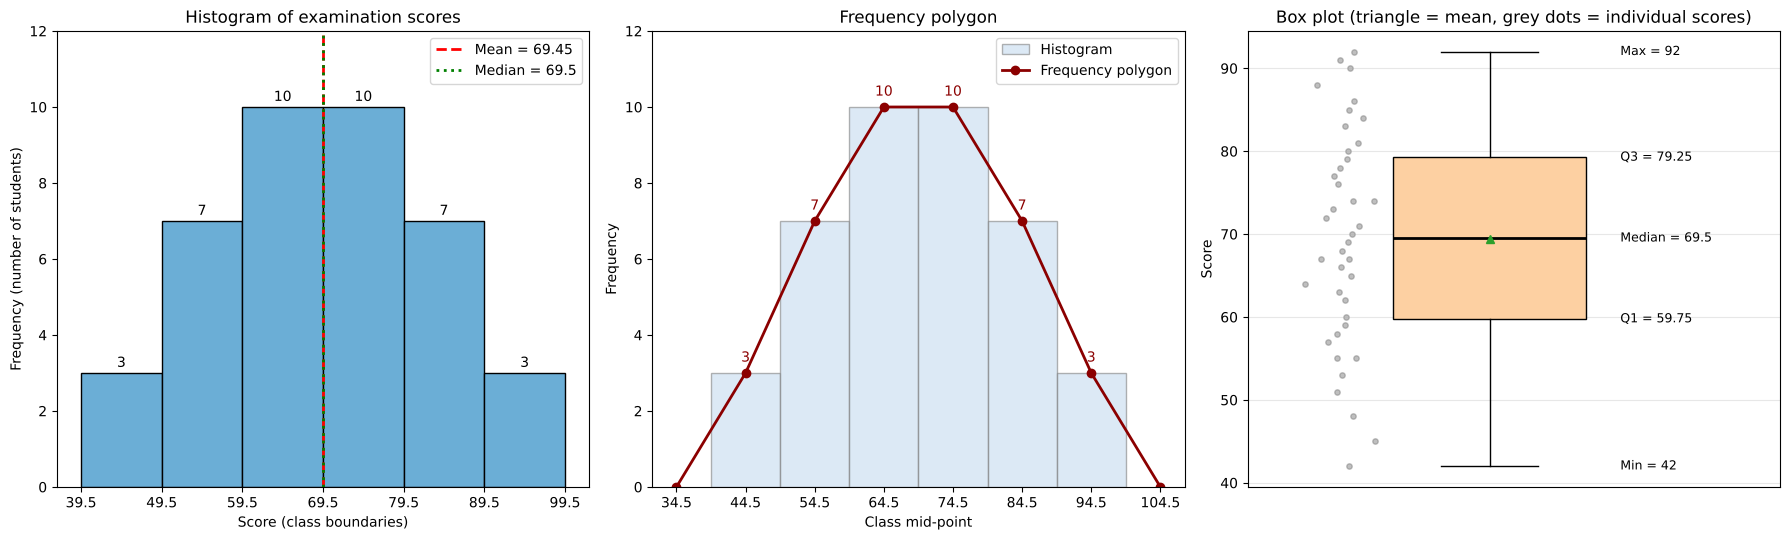

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Histogram on class boundaries
ax = axes[0]
counts, edges, patches = ax.hist(scores, bins=boundaries, color="#6baed6", edgecolor="black")
ax.bar_label(patches, labels=[int(c) for c in counts], padding=2)
ax.axvline(mean_raw, color="red", ls="--", lw=2, label=f"Mean = {mean_raw:.2f}")
ax.axvline(median_raw, color="green", ls=":", lw=2, label=f"Median = {median_raw}")
ax.set_xticks(boundaries)
ax.set_xlabel("Score (class boundaries)")
ax.set_ylabel("Frequency (number of students)")
ax.set_title("Histogram of examination scores")
ax.set_ylim(0, 12)
ax.legend()

# 2. Frequency polygon (closed with zero-frequency classes at both ends)
ax = axes[1]
poly_x = np.concatenate(([x_mid[0] - h], x_mid, [x_mid[-1] + h]))     # 34.5 ... 104.5
poly_y = np.concatenate(([0], fr, [0]))
ax.hist(scores, bins=boundaries, color="#c6dbef", edgecolor="grey", alpha=0.6, label="Histogram")
ax.plot(poly_x, poly_y, marker="o", color="darkred", lw=2, label="Frequency polygon")
for xx, yy in zip(x_mid, fr):
    ax.text(xx, yy + 0.3, str(yy), ha="center", color="darkred")
ax.set_xticks(poly_x)
ax.set_xlabel("Class mid-point")
ax.set_ylabel("Frequency")
ax.set_title("Frequency polygon")
ax.set_ylim(0, 12)
ax.legend()

# 3. Box plot with the five-number summary written next to it
ax = axes[2]
ax.boxplot(scores, patch_artist=True, showmeans=True, widths=0.4,
           boxprops=dict(facecolor="#fdd0a2"), medianprops=dict(color="black", lw=2))
for val, name in [(scores.min(), "Min"), (q1_lin, "Q1"), (median_raw, "Median"), (q3_lin, "Q3"), (scores.max(), "Max")]:
    ax.text(1.27, val, f"{name} = {val:g}", va="center", fontsize=9)
ax.scatter(np.random.default_rng(1).normal(0.7, 0.03, n), scores, alpha=0.5, s=15, color="grey")
ax.set_xticks([])
ax.set_xlim(0.5, 1.6)
ax.set_ylabel("Score")
ax.set_title("Box plot (triangle = mean, grey dots = individual scores)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

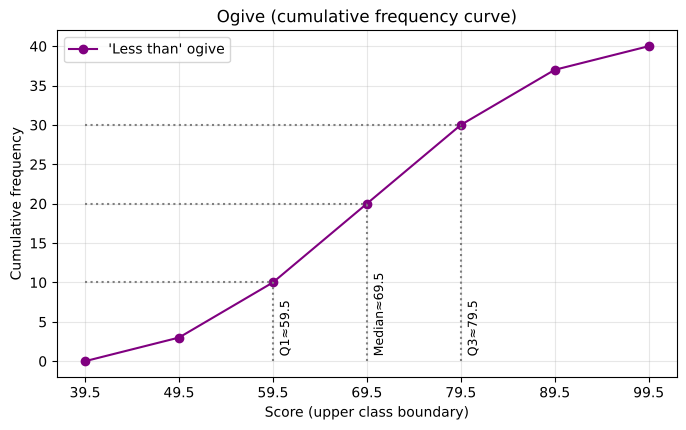

In [13]:
# Bonus: cumulative frequency curve (ogive) - read the median and quartiles off the graph
plt.figure(figsize=(8, 4.5))
plt.plot(boundaries, np.concatenate(([0], cf)), marker="o", color="purple", label="'Less than' ogive")
for p, name in [(0.25, "Q1"), (0.5, "Median"), (0.75, "Q3")]:
    val = grouped_quantile(p)
    plt.hlines(p * n, boundaries[0], val, colors="grey", ls=":")
    plt.vlines(val, 0, p * n, colors="grey", ls=":")
    plt.text(val + 0.7, 1, f"{name}≈{val:.1f}", rotation=90, fontsize=9)
plt.xticks(boundaries)
plt.xlabel("Score (upper class boundary)")
plt.ylabel("Cumulative frequency")
plt.title("Ogive (cumulative frequency curve)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## (g) Outlier detection with the IQR method  *(10 marks)*

$$\text{Lower fence} = Q1 - 1.5 \times IQR \qquad \text{Upper fence} = Q3 + 1.5 \times IQR$$

Any score outside the fences is a potential outlier.

In [14]:
for name, q1_, q3_ in [("Linear (default)", q1_lin, q3_lin), ("(n+1)p textbook", q1_tb, q3_tb)]:
    iqr_ = q3_ - q1_
    lo_f, hi_f = q1_ - 1.5 * iqr_, q3_ + 1.5 * iqr_
    outl = scores[(scores < lo_f) | (scores > hi_f)]
    print(f"{name:17s}: IQR = {iqr_:.3f}, fences = [{lo_f:.3f}, {hi_f:.3f}] -> outliers: {outl.tolist() if outl.size else 'NONE'}")

print(f"\nLowest score {scores.min()} and highest score {scores.max()} are both inside the fences.")
z = (scores - mean_raw) / sd_s
print(f"z-scores range from {z.min():.2f} to {z.max():.2f} -> no score beyond ±3 SD either.")

Linear (default) : IQR = 19.500, fences = [30.500, 108.500] -> outliers: NONE
(n+1)p textbook  : IQR = 20.500, fences = [28.500, 110.500] -> outliers: NONE

Lowest score 42 and highest score 92 are both inside the fences.
z-scores range from -2.09 to 1.72 -> no score beyond ±3 SD either.


**No outliers are present.** To *examine the effect* that outliers would have on the summary statistics, we compare:
1. the original data,
2. the data **without the two most extreme scores** (42 and 92), a trimming check, and
3. the data with a **hypothetical outlier**, e.g. a data-entry error where one student's 42 is recorded as **4**.

In [15]:
def summary(arr):
    q1_, med_, q3_ = np.percentile(arr, [25, 50, 75])
    return {"n": len(arr), "Mean": arr.mean(), "Median": med_, "SD (ddof=1)": arr.std(ddof=1),
            "Range": np.ptp(arr), "IQR": q3_ - q1_, "CV %": arr.std(ddof=1) / arr.mean() * 100}

trimmed = np.sort(scores)[1:-1]                     # drop the min (42) and max (92)
with_outlier = scores.copy()
with_outlier[np.argmin(scores)] = 4                 # hypothetical error: 42 typed as 4

effect = pd.DataFrame({
    "Original": summary(scores),
    "Without min & max": summary(trimmed),
    "With outlier (42 -> 4)": summary(with_outlier),
}).T
display(effect.round(3))

q1o, q3o = np.percentile(with_outlier, [25, 75])
print(f"In the hypothetical data the lower fence is {q1o - 1.5 * (q3o - q1o):.3f}, so the score 4 is flagged as an outlier.")
print("Change caused by ONE outlier:")
for col in ["Mean", "Median", "SD (ddof=1)", "Range", "IQR"]:
    print(f"   {col:12s}: {effect.loc['Original', col]:8.3f} -> {effect.loc['With outlier (42 -> 4)', col]:8.3f}")

,n,Mean,Median,SD (ddof=1),Range,IQR,CV %
Original,40.0000,69.4500,69.5000,13.1270,50.0000,19.5000,18.9010
Without min & max,38.0000,69.5790,69.5000,12.1450,46.0000,18.2500,17.4550
With outlier (42 -> 4),40.0000,68.5000,69.5000,16.1830,88.0000,19.5000,23.6250


In the hypothetical data the lower fence is 30.500, so the score 4 is flagged as an outlier.
Change caused by ONE outlier:
   Mean        :   69.450 ->   68.500
   Median      :   69.500 ->   69.500
   SD (ddof=1) :   13.127 ->   16.183
   Range       :   50.000 ->   88.000
   IQR         :   19.500 ->   19.500


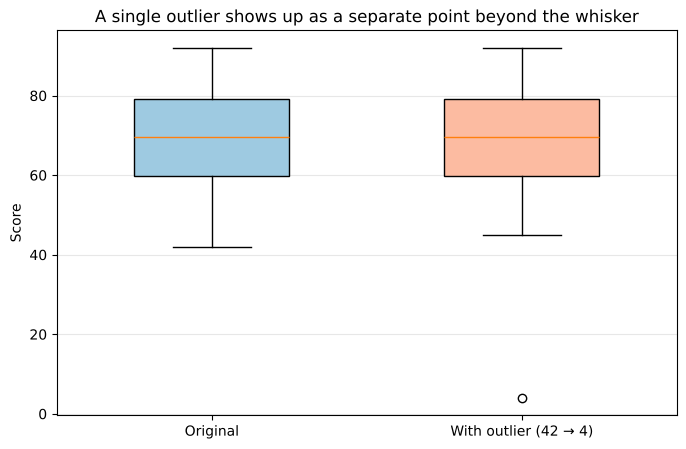

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([scores, with_outlier], patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], ["#9ecae1", "#fcbba1"]):
    patch.set_facecolor(c)
ax.set_xticks([1, 2])
ax.set_xticklabels(["Original", "With outlier (42 → 4)"])
ax.set_ylabel("Score")
ax.set_title("A single outlier shows up as a separate point beyond the whisker")
ax.grid(axis="y", alpha=0.3)
plt.show()

**Effect of outliers:** one extreme value pulls the **mean** down by about 1 mark (69.45 → 68.50), increases the **SD** (13.13 → 16.18) and **CV** (18.9% → 23.6%), and inflates the **range** from 50 to 88. The **median and IQR barely change**. This is why the median and IQR are called **robust (resistant) statistics**, while the mean, SD and range are **sensitive** to outliers. In the real data, no outliers exist, and removing the two extreme scores changes the mean by only 0.13 (69.45 → 69.58), so all summary statistics are reliable.

## (h) Interpretation and how to report overall performance  *(10 marks)*

In [17]:
# Additional facts for the interpretation
print(f"Students scoring 60-79 : {np.sum((scores >= 60) & (scores <= 79))} of {n} ({np.mean((scores >= 60) & (scores <= 79)) * 100:.0f}%)")
print(f"Students scoring >= 80 : {np.sum(scores >= 80)} ({np.mean(scores >= 80) * 100:.1f}%)")
print(f"Students scoring < 50  : {np.sum(scores < 50)} ({np.mean(scores < 50) * 100:.1f}%) -> {sorted(scores[scores < 50].tolist())}")
print(f"Skewness = {stats.skew(scores, bias=False):.4f} (0 = perfectly symmetric)")
print(f"Excess kurtosis = {stats.kurtosis(scores, bias=False):.4f} (0 = normal; negative = flatter than normal)")

Students scoring 60-79 : 20 of 40 (50%)
Students scoring >= 80 : 10 (25.0%)
Students scoring < 50  : 3 (7.5%) -> [42, 45, 48]
Skewness = -0.1526 (0 = perfectly symmetric)
Excess kurtosis = -0.7133 (0 = normal; negative = flatter than normal)


### Interpretation of the distribution

1. **Centre:** the typical score is about **69.5** (mean 69.45, median 69.5, grouped mode ≈ 69.5). Because the three measures agree, the distribution is **symmetric**. The grouped frequencies **3, 7, 10, 10, 7, 3** are a mirror image, and the skewness is close to 0 (−0.15).
2. **Spread:** the SD is **13.13 marks** (sample) and the IQR about **19.5–20.5 marks** depending on the quartile method, so the middle 50% of students score between about 60 and 80. The range is 50 (42 to 92). **CV = 18.9%** indicates **moderate** relative variability: the class is reasonably homogeneous but not tightly clustered.
3. **Shape:** the distribution is bell-shaped and slightly flatter than a normal curve (negative excess kurtosis). 62.5% of scores fall within ±1 SD and 97.5% within ±2 SD, close to the normal benchmarks of 68% and 95%.
4. **Groups:** **50% of students (20/40)** scored 60–79. **25% (10)** scored 80 or above. **3 students (7.5%)** scored below 50 (42, 45, 48) and need academic support.
5. **No outliers:** the IQR method flags no scores, so no single student distorts the summary.

### Recommended way to report overall performance

* **Main summary: mean ± SD.** Because the data is symmetric with no outliers, report **"mean = 69.45, SD = 13.13 (n = 40)"**. Add the **median (69.5) and IQR (Q1 ≈ 60, Q3 ≈ 79)** as a robust confirmation. If a future cohort is skewed or has outliers, lead with median and IQR instead.
* **Show the distribution:** include the **frequency table with percentage and cumulative %** (e.g. "75% of students scored below 80") and a **histogram or box plot**, so readers see the full spread, not just the average.
* **Report bands or grades:** present the percentage of students in each band (below 50, 50–59, …, 90+) and identify the at-risk students (scores < 50) for follow-up.
* **Use the CV** when comparing this exam with other exams or cohorts, since it is unit-free.
* Avoid reporting the raw **mode**: the data is multimodal and the modal value is not meaningful.